In [1]:
pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 18.3 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.6 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 94.7 MB/s eta 0:00:00:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 74.3 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 35.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.3 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.1 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 29.2 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 12.9 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 2.2 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 67.4 MB/s eta 0:00:00:00:0100:01
  Attempting uninst

In [1]:
import os
import cv2
import numpy as np
from PIL import Image
from imutils import contours
import matplotlib.pyplot as plt
import pytesseract
from ultralytics import YOLO
#from sklearn.metrics.pairwise import cosine_similarity

In [2]:
def text_detection(img_path, text_det_model):
    text_det_results = text_det_model(img_path, verbose=False)[0]
    bboxes = text_det_results.boxes.xyxy.tolist()
    classes = text_det_results.boxes.cls.tolist()
    names = text_det_results.names
    confs = text_det_results.boxes.conf.tolist()
    return bboxes, classes, names, confs

def draw_detections(img, detections):
    """Draw bounding boxes on an image."""
    fig, ax = plt.subplots()
    ax.imshow(img)
    ax.axis('off')

    for bbox in detections:
        x1, y1, x2, y2 = bbox
        rect = plt.Rectangle((x1, y1), x2 - x1, y2 - y1,
                             edgecolor='red', facecolor='none', linewidth=2)
        ax.add_patch(rect)
    fig.canvas.draw()
    # Convert figure to numpy image
    width, height = fig.canvas.get_width_height()
    image_array = np.frombuffer(fig.canvas.tostring_rgb(), dtype=np.uint8).reshape(height, width, 3)
    plt.close(fig)
    return image_array

def predict(img_path, bboxes):
    # Load the image
    img = Image.open(img_path).convert('RGB')

    # Draw and return the annotated image
    annotated_img = draw_detections(img, bboxes)
    return annotated_img

In [3]:
def split_bounding_boxes(img_path, bboxes):
    #os.makedirs(save_dir, exist_ok=True)
    cropped_imgs = []
    count = 0
    img = Image.open(img_path).convert("L")  # Convert to grayscale for np.mean
    for bb in bboxes:
        # If bb is in (x1, y1, x2, y2) format
        cropped_img = img.crop((bb[0], bb[1], bb[2], bb[3]))
        

        # Convert to NumPy for pixel value checking
        cropped_arr = np.array(cropped_img)

        # Filter out nearly black or white
        if np.mean(cropped_arr) < 35 or np.mean(cropped_arr) > 220:
            continue
        if cropped_img.size[0] < 10 or cropped_img.size[1] < 10:
            continue
        cropped_imgs.append(cropped_img)
    
    return cropped_imgs

def create_char_imgs(img_path, bboxes, padding = 10, min_area = 50, min_width = 5, min_height = 20):  
    '''
    padding: adjust the bb expansion
    min_area: filter out too-small contours
    min_width: minimum contour width
    min_height: minimum contour height
    '''
    char_batch = []
    cropped_imgs = split_bounding_boxes(img_path, bboxes)

    for i, img in enumerate(cropped_imgs):
        x1, y1, x2, y2 = bboxes[i] # bb of each cropped image 
        image = np.array(img)
        # Threshold
        thresh = cv2.threshold(image,0,255,cv2.THRESH_OTSU + cv2.THRESH_BINARY)[1] 
        # Find contours
        cnts = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE) 
        cnts = cnts[0] if len(cnts) == 2 else cnts[1] 
        cnts, _ = contours.sort_contours(cnts, method="top-to-bottom") if y2 - y1 > x2 - x1 else contours.sort_contours(cnts, method="left-to-right") 

        char_imgs = []
        ROI_number = 0
        for c in cnts:
            area = cv2.contourArea(c) 
            x, y, w, h = cv2.boundingRect(c)
            aspect_ratio = w / float(h)
            # Filtering: remove tiny specks and extremely thin/wide shapes
            if area > min_area and w > min_width and h > min_height and 0.2 < aspect_ratio < 5:
                # Expand bounding box
                x_new = max(x - padding, 0)
                y_new = max(y - padding, 0)
                w_new = min(w + 2*padding, image.shape[1] - x_new)
                h_new = min(h + 2*padding, image.shape[0] - y_new)

                ROI = image[y_new:y_new+h_new, x_new:x_new+w_new] 
                char_imgs.append(ROI) 

        char_batch.append(char_imgs)
    
    return char_batch

def create_horizontal_strip(char_imgs, spacing=5):
    if len(char_imgs) == 0:
        return None
    # Chiều cao cố định
    target_height = max(c.shape[0] for c in char_imgs)
    resized_chars = [
        cv2.resize(c, (int(c.shape[1] * target_height / c.shape[0]), target_height))
        for c in char_imgs
    ]
    # Lấy màu nền trung bình từ ảnh đầu tiên (có thể đổi tùy ý)
    background_color = int(np.mean([
        np.mean(c[:, 0]) for c in resized_chars  # Lấy cột đầu tiên làm nền
    ]))
    strip_parts = []
    for c in resized_chars:
        strip_parts.append(c)
        strip_parts.append(
            np.full((target_height, spacing), background_color, dtype=np.uint8)
        )
    horizontal_strip = np.hstack(strip_parts[:-1])  # bỏ spacing cuối cùng
    return horizontal_strip


def run_tesseract_on_image(img, psm: int = 7, oem: int = 3, whitelist: str = 'ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789'):
    """Run Tesseract with sensible options for single-line alphanumeric.
    psm 7 = treat image as a single text line. psm 8 = single word. Try 7.
    """
    config = f'-c tessedit_char_whitelist={whitelist} --psm {psm} --oem {oem}'
    text = pytesseract.image_to_string(img, config=config)
    text = text.strip()
    text = text.replace('\n','')
    text = ''.join([c for c in text if c.isalnum()])
    return text

In [4]:
def preprocess_for_tesseract(img: np.ndarray) -> np.ndarray:
    """Convert to grayscale and apply thresholding to help Tesseract.
    Returns a PIL Image (recommended format for pytesseract.image_to_string).
    """
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    # adaptive threshold
    th = cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                               cv2.THRESH_BINARY_INV, 15, 9)
    # invert back so text is dark on light background
    inv = cv2.bitwise_not(th)
    pil = Image.fromarray(inv)
    return pil


In [5]:
# ---------- ISO 6346 helpers & character correction ----------

CHAR_CORRECTION_OWNER = {'0':'O', '1':'I', 'l':'I', 'L':'I', 'O':'O', 'o':'O'}
CHAR_CORRECTION_SERIAL = {'O':'0','I':'1','S':'5','G':'6','B':'8'}

In [6]:
def apply_character_level_corrections(candidate: str) -> str:
    """Given a raw OCR string (likely the concatenation of owner+serial+checkdigit),
    try to correct common confusions. This function is heuristic — tune for your data.
    """
    # If input is short, just return upper
    s = candidate.upper()
    # replace common owner prefix mistakes (first 4 chars expected letters)
    if len(s) >= 4:
        prefix = list(s[:4])
        for i,ch in enumerate(prefix):
            if ch in CHAR_CORRECTION_OWNER:
                prefix[i] = CHAR_CORRECTION_OWNER[ch]
        s = ''.join(prefix) + s[4:]
    # For digits in the serial region (6 digits) try correcting known confusions
    # naive approach: find first run of 6 digits/letters and correct letters to digits
    # We'll attempt to locate a 6-length numeric-ish substring.
    # Simple fallback: convert characters in serial position (after 4) using map
    if len(s) >= 11:
        serial_part = list(s[4:10])
        for i,ch in enumerate(serial_part):
            if ch in CHAR_CORRECTION_SERIAL:
                serial_part[i] = CHAR_CORRECTION_SERIAL[ch]
        s = s[:4] + ''.join(serial_part) + s[10:]
    return s



In [8]:
def compute_iso6346_check_digit(owner_prefix: str, serial: str) -> int:
    """Compute ISO 6346 check digit for owner_prefix (3 or 4 letters?) + serial (6 digits).
    Implementation follows ISO 6346 algorithm.
    """
    # Full box format: 4-letter owner (3-letter owner + category letter) + 6-digit serial
    # Character values: letters A-Z -> values as specified (A=10, B=12, C=13...), see standard mapping
    # We use the mapping described in ISO 6346 (power of 2 weighting)
    trans = {}
    # letters values: A=10, B=12, C=13, D=14, E=15, F=16, G=17, H=18, I=19, J=20,
    # K=21, L=23, M=24, N=25, O=26, P=27, Q=28, R=29, S=30, T=31, U=32, V=34, W=35, X=36, Y=37, Z=38
    # Note some values skip numbers (this is how ISO specifies)
    letters = list('ABCDEFGHIJKLMNOPQRSTUVWXYZ')
    letter_values = [10,12,13,14,15,16,17,18,19,20,21,23,24,25,26,27,28,29,30,31,32,34,35,36,37,38]
    trans.update({letters[i]: letter_values[i] for i in range(len(letters))})
    # digits
    for d in '0123456789':
        trans[d] = int(d)
    # Now build full string (owner 4 chars + serial 6 chars). If owner_prefix is 3 letters, user must include category.
    code = (owner_prefix + serial)
    # weights are 2^i for i position from left (starting at 0)
    total = 0
    for i, ch in enumerate(code):
        if ch not in trans:
            # unknown char, treat as 0
            val = 0
        else:
            val = trans[ch]
        weight = 2 ** i
        total += val * weight
    remainder = total % 11
    check = remainder
    if check == 10:
        check = 0
    return check


In [9]:
# # ---------- High-level pipeline function ----------

# def model2_pipeline(image_path: str, model, debug: bool = True) -> Dict:
#     """Given full image and a loaded YOLO char detector, run the Model 2 pipeline and return structured result.
#     Returns: { 'raw_ocr': str, 'corrected': str, 'owner': str, 'serial': str, 'check_digit': str, 'valid_check_digit': bool }
#     """
#     img = cv2.imread(image_path)
#     if img is None:
#         raise FileNotFoundError(f'Could not read image: {image_path}')
#     orig = img.copy()
#     dets = detect_characters(model, img, conf_thres=0.2)
#     if debug:
#         print('Detected boxes:', len(dets))
#     if len(dets) == 0:
#         return {'error': 'no_detections'}
#     boxes = [d['xyxy'] for d in dets]
#     vertical = is_vertical_layout(boxes)
#     if debug:
#         print('Vertical layout?', vertical)
#     sorted_dets = sort_boxes_reading_order(dets, vertical)
#     merged_img, merged_boxes = merge_crops_horizontal(img, sorted_dets, pad=6)
#     if merged_img is None:
#         return {'error': 'merge_failed'}
#     merged_path = os.path.join(OUT_DIR, 'merged_chars.jpg')
#     cv2.imwrite(merged_path, merged_img)
#     pil = preprocess_for_tesseract(merged_img)
#     raw = run_tesseract_on_image(pil, psm=7)
#     if debug:
#         print('Raw OCR ->', raw)
#     corrected = apply_character_level_corrections(raw)
#     # Parse into owner(4), serial(6), check(1) if possible
#     owner = corrected[:4] if len(corrected) >= 4 else ''
#     serial = corrected[4:10] if len(corrected) >= 10 else ''
#     check_digit = corrected[10] if len(corrected) >= 11 else ''
#     valid_check = None
#     if owner and serial and len(serial) == 6 and len(owner) == 4 and check_digit.isdigit():
#         computed = compute_iso6346_check_digit(owner, serial)
#         valid_check = (computed == int(check_digit))
#     else:
#         valid_check = False
#     result = {'raw_ocr': raw, 'corrected': corrected, 'owner': owner, 'serial': serial, 'check_digit': check_digit, 'valid_check_digit': valid_check, 'merged_image': merged_path}
#     return result

# YOLO_WEIGHTS = '/kaggle/input/detect/pytorch/default/1/best.pt'  # <-- path to your YOLO char detection weights
# EXAMPLE_IMAGE_PATH = '/kaggle/input/container-id-number/test/images/1-133122001-OCR-LF-C01_jpg.rf.dd82d6c014771ef82cef74a41e2b6d63.jpg'  # <-- example container image
# OUT_DIR = 'model2_outputs'
# os.makedirs(OUT_DIR, exist_ok=True)

# # ---------- Example run (edit paths as needed) ----------
# if __name__ == '__main__':
#     print('Loading YOLO model from', YOLO_WEIGHTS)
#     model = load_yolo_model(YOLO_WEIGHTS)
#     print('Model loaded. Running pipeline on', EXAMPLE_IMAGE_PATH)
#     res = model2_pipeline(EXAMPLE_IMAGE_PATH, model, debug=True)
#     print('\nResult:')
#     for k,v in res.items():
#         print(k, ':', v)
#     print('\nOutputs saved to', OUT_DIR)


C:\Users\acer\AppData\Local\Temp\ipykernel_11028\3445540639.py:23: MatplotlibDeprecationWarning: The tostring_rgb function was deprecated in Matplotlib 3.8 and will be removed in 3.10. Use buffer_rgba instead.
  image_array = np.frombuffer(fig.canvas.tostring_rgb(), dtype=np.uint8).reshape(height, width, 3)


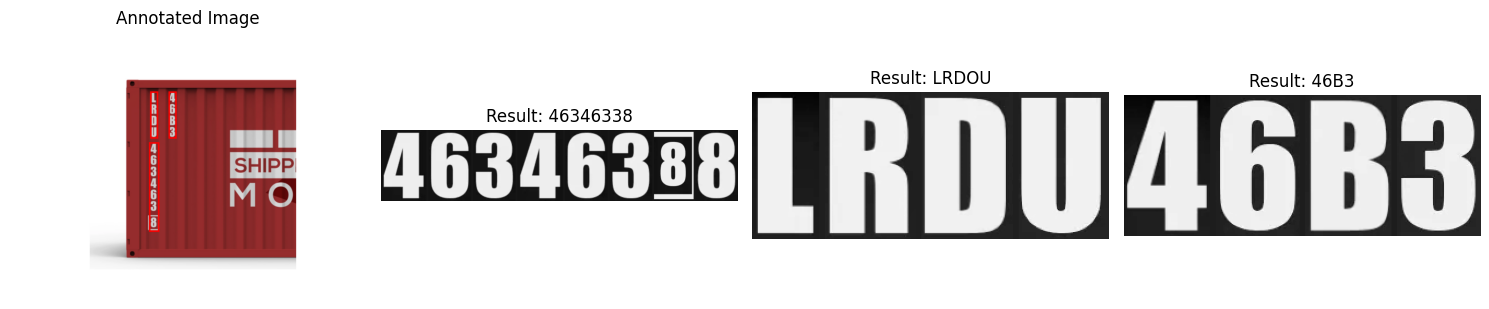

{'number': '46346338', 'company': 'LRDOU', 'size': '46B3'}


In [7]:
model = YOLO('detect/train/weights/best.pt')

img_path = ('./FULL4_2500x.webp')
bboxes, classes, names, confs = text_detection(img_path, model)
annotated_image= predict(img_path, bboxes)
char_batch = create_char_imgs(img_path, bboxes, padding = 5)

container_dict = {}
fig, ax = plt.subplots(1, len(char_batch)+1, figsize=(15,5))
ax[0].imshow(annotated_image, cmap='gray')
ax[0].axis('off')
ax[0].set_title("Annotated Image")
i = 0
for img in char_batch:
    horizontal_strip = create_horizontal_strip(img, spacing=5)
    if horizontal_strip is None: 
        continue
    result = run_tesseract_on_image(horizontal_strip, psm=7)
    container_dict[names[classes[i]]] = result
    ax[i+1].imshow(horizontal_strip, cmap='gray')
    ax[i+1].axis('off')
    ax[i+1].set_title(f"Result: {result}")
    i += 1
plt.tight_layout()
plt.show()

print(container_dict)

In [38]:
print(container_dict)

{'company': 'BSU', 'number': '2351589', 'size': '2261'}


In [11]:
a = [12, 19, 13, 32, 1, 2, 3, 4, 5, 6]
result = 1
for i in range(10):
    result += a[i] * 2**(i)

result%11 - 1

5